# Relief Radar 01 — The snapshot and the population

Every number here is read from build artefacts (`reports/snapshot_gate.json`, `reports/parts/dataset_build.json`, `reports/parts/model_results.json`), so this notebook re-executes in seconds and can never drift from the pipeline outputs.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

gate = json.load(open('../reports/snapshot_gate.json'))
build = json.load(open('../reports/parts/dataset_build.json'))
print('rows:', f"{gate['rows']:,}")
print('narrative column in bulk file:', gate['has_narrative_column'])
print('date range:', gate['date_received_min'], 'to', gate['date_received_max'])
print('bulk zip sha256:', gate['bulk_zip_sha256'][:16], '...')
gate['columns']

rows: 19,045,222
narrative column in bulk file: False
date range: 2011-12-01 to 2026-11-10
bulk zip sha256: db66181722a6a49b ...


['Date received',
 'Product',
 'Sub-product',
 'Issue',
 'Sub-issue',
 'Company public response',
 'Company',
 'State',
 'ZIP code',
 'Tags',
 'Submitted via',
 'Date sent to company',
 'Company response to consumer',
 'Timely response?',
 'Complaint ID']

## How complaints close (full file)

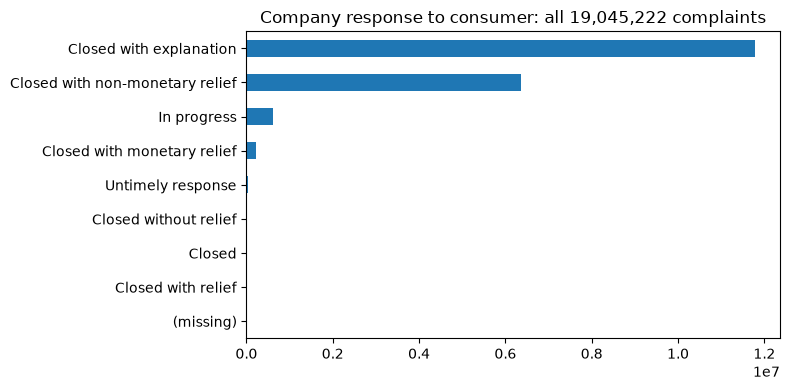

(missing)                                21
Closed with relief                     5304
Closed                                17611
Closed without relief                 17867
Untimely response                     36055
Closed with monetary relief          225085
In progress                          618977
Closed with non-monetary relief     6350988
Closed with explanation            11773314
dtype: int64

In [2]:
resp = pd.Series(gate['response_distribution']).sort_values(ascending=True)
resp.plot(kind='barh', figsize=(8, 4))
plt.title('Company response to consumer: all 19,045,222 complaints')
plt.tight_layout(); plt.show()
resp

## The primary population

The modelling population keeps only unambiguous closures: "Closed with monetary relief" (positive) against "Closed with explanation", "Closed with non-monetary relief" and "Closed without relief". In-progress, untimely, legacy ambiguous labels and missing responses are excluded and counted, never dropped silently (see docs/leakage_audit.md).

primary population: 18,367,254
positives: 225,085
base rate: 1.225 %
unique raw company names: 8,212


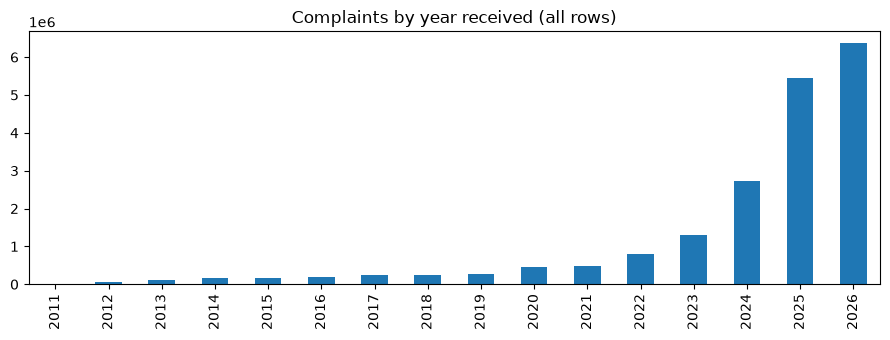

2011       2536
2012      72368
2013     108214
2014     152908
2015     168272
2016     191292
2017     242745
2018     257130
2019     277239
2020     444212
2021     495940
2022     800245
2023    1292043
2024    2734252
2025    5442927
2026    6362899
Name: complaints, dtype: int64

In [3]:
comp = build['complaints']
print('primary population:', f"{comp['primary_population_rows']:,}")
print('positives:', f"{comp['positives_monetary_relief']:,}")
print('base rate:', round(100 * comp['positives_monetary_relief'] / comp['primary_population_rows'], 3), '%')
print('unique raw company names:', f"{comp['unique_companies_raw']:,}")
years = pd.Series(comp['rows_by_year']).rename('complaints')
years.index = years.index.astype(int)
years.plot(kind='bar', figsize=(9, 3.5))
plt.title('Complaints by year received (all rows)')
plt.tight_layout(); plt.show()
years

## Era drift in the outcome itself

The monetary-relief base rate collapses across eras as complaint volume shifts toward credit reporting. This is why the evaluation is a temporal split with era base rates reported beside every sample metric, and why a single headline AUC must be read with the within-product subgroups (notebook 02).

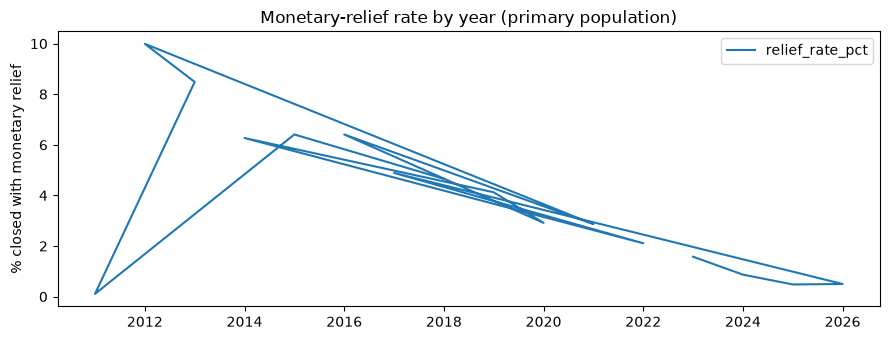

,n,relief_rate,relief_rate_pct
2023,1291333.0,0.015763,1.576278
2024,2732755.0,0.008689,0.868903
2025,5433267.0,0.004809,0.480852
2026,5727250.0,0.004988,0.498756
2017,240309.0,0.048891,4.889122
2022,799673.0,0.021074,2.107361
2014,149069.0,0.062689,6.268909
2019,276201.0,0.041238,4.123808
2020,443363.0,0.029161,2.916121
2016,186803.0,0.064089,6.408891


In [4]:
models = json.load(open('../reports/parts/model_results.json'))
era = pd.DataFrame(models['era_base_rates_full_population']).T
era.index = era.index.astype(int)
era['relief_rate_pct'] = 100 * era['relief_rate']
era[['n', 'relief_rate_pct']].plot(y='relief_rate_pct', figsize=(9, 3.5))
plt.title('Monetary-relief rate by year (primary population)')
plt.ylabel('% closed with monetary relief')
plt.tight_layout(); plt.show()
era

## The narrative layer

The live bulk file no longer carries narratives (publication ceased 2026-08-14). The narrative corpus used here is the CFPB FOIA Reading Room archive: narrative-bearing means a non-empty narrative in that archive for the Complaint ID.

In [5]:
narr = build['narratives']
print('narrative rows extracted:', f"{narr['narrative_rows']:,}")
print('duplicate IDs dropped:', narr['duplicate_ids_dropped'])
audit = json.load(open('../reports/parts/selection_audit.json'))
pop = audit['population']
for k, v in pop.items():
    print(k, ':', v)

narrative rows extracted: 3,851,415
duplicate IDs dropped: 0
primary_rows_in_window : 16782339
narrative_rows_in_window : 3836347
narrative_share : 0.2285942978508538
relief_rate_narrative : 0.025826391616816727
relief_rate_no_narrative : 0.007290596193787235
